**1. Load the Dataset**

First, the dataset is loaded and the column names are cleaned so they are easier to work with in Python.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Use '../' to step out of 'notebooks' and go into 'data'
data_path = "../data/Teen_Mental_Health_Dataset.csv"

# Load the dataset
df = pd.read_csv(data_path)

# Clean column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)


# Look at the first few rows to make sure it worked
df.head()

,age,gender,daily_social_media_hours,platform_usage,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,social_interaction_level,stress_level,anxiety_level,addiction_level,depression_label
0,14,male,7.9,Instagram,7.4,2.9,3.01,1.5,low,2,2,1,0
1,19,female,1.9,TikTok,8.0,2.9,3.22,0.8,high,8,1,10,0
2,17,female,1.3,Instagram,7.6,0.5,3.92,0.0,high,2,4,2,0
3,15,male,7.4,TikTok,6.9,1.6,3.48,0.8,medium,1,7,9,0
4,15,female,4.7,Both,4.9,3.0,2.37,1.4,medium,3,5,2,0


In [5]:
df.shape

(1200, 13)

**2. Basic Dataset Information**

This section checks the structure of the dataset, data types, and missing values.

In [6]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
df.describe()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       1200 non-null   int64  
 1   gender                    1200 non-null   str    
 2   daily_social_media_hours  1200 non-null   float64
 3   platform_usage            1200 non-null   str    
 4   sleep_hours               1200 non-null   float64
 5   screen_time_before_sleep  1200 non-null   float64
 6   academic_performance      1200 non-null   float64
 7   physical_activity         1200 non-null   float64
 8   social_interaction_level  1200 non-null   str    
 9   stress_level              1200 non-null   int64  
 10  anxiety_level             1200 non-null   int64  
 11  addiction_level           1200 non-null   int64  
 12  depression_label          1200 non-null   int64  
dtypes: float64(5), int64(5), str(3)
memory usage: 122.0 K

,age,daily_social_media_hours,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,stress_level,anxiety_level,addiction_level,depression_label
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,15.928333,4.536667,6.449417,1.740333,2.990383,1.014500,5.445833,5.636667,5.565000,0.025833
std,2.021947,2.029599,1.442677,0.716660,0.576758,0.582185,2.903290,2.859453,2.830627,0.158704
min,13.000000,1.000000,4.000000,0.500000,2.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,14.000000,2.800000,5.200000,1.100000,2.500000,0.500000,3.000000,3.000000,3.000000,0.000000
50%,16.000000,4.500000,6.500000,1.800000,2.990000,1.000000,5.000000,6.000000,6.000000,0.000000
75%,18.000000,6.300000,7.600000,2.400000,3.480000,1.500000,8.000000,8.000000,8.000000,0.000000
max,19.000000,8.000000,9.000000,3.000000,4.000000,2.000000,10.000000,10.000000,10.000000,1.000000


**3. Target Variable Distribution**

The target variable is stress_level. Before modeling, it is important to inspect how stress levels are distributed.

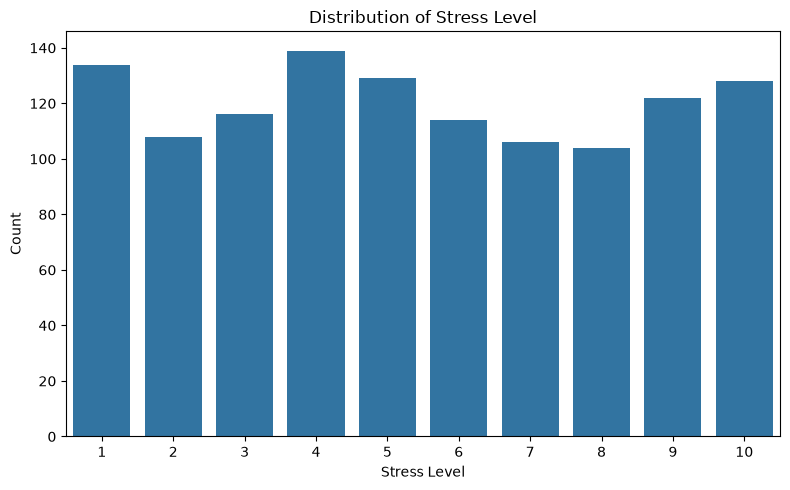

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x="stress_level",
    data=df
)
#the code structure -----function_name(parameter = value)

plt.title("Distribution of Stress Level")
plt.xlabel("Stress Level")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

**4. Correlation Analysis**

Correlation analysis is used to check whether the numerical variables have strong linear relationships with stress_level.

A high positive correlation means that stress increases as the feature increases.

A high negative correlation means that stress decreases as the feature increases.

In [8]:
correlation_matrix = df.select_dtypes(
    include=["number"]
).corr()

stress_corr = correlation_matrix[
    "stress_level"
].sort_values(ascending=False)

print("Correlation with stress_level:")
print(stress_corr)

Correlation with stress_level:
stress_level                1.000000
depression_label            0.170474
daily_social_media_hours    0.030698
anxiety_level               0.015811
physical_activity           0.012159
addiction_level            -0.000129
academic_performance       -0.000600
screen_time_before_sleep   -0.008650
sleep_hours                -0.010979
age                        -0.031208
Name: stress_level, dtype: float64


**5. Correlation Heatmap**

The heatmap provides a visual overview of relationships between numerical variables.

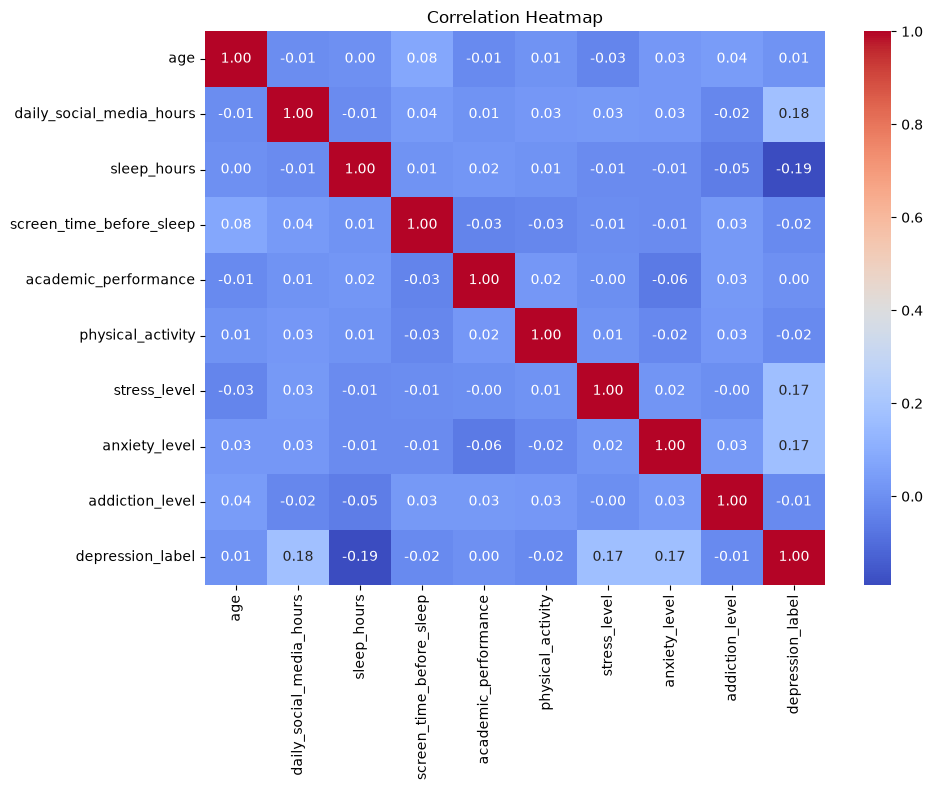

In [9]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()